# HW04：降维、PCA 与 UMAP

- 姓名：赵晨雨
- 学号：38720260158057
- 初步判断：不同意“二维图分开就证明发现疾病机制并能预测新患者”；初始信心：80/100。
- 初步时不确定需要补充什么证据；完成分析后再更新判断。

本报告用 Golub 白血病数据练习降维和证据边界。代码会从课程仓库读取数据，保留实际运行结果、表格和图。描述性分析不等同于新患者预测；探针权重也不能直接解释为致病基因。

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import umap
from IPython.display import display

plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False

def find_repo_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        data_file = candidate / 'assignments' / 'hw04' / 'resources' / 'data' / 'leukemia' / 'leukemia.csv'
        if data_file.exists():
            return candidate
    raise FileNotFoundError('无法从当前目录向上找到 HW04 数据文件。')

ROOT = find_repo_root()
DATA_PATH = ROOT / 'assignments' / 'hw04' / 'resources' / 'data' / 'leukemia' / 'leukemia.csv'
RESULTS_DIR = ROOT / '.tmp' / 'dimension-reduction' / 'student-results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)
metadata_columns = ['sample_id', 'original_split', 'diagnosis']
feature_columns = [column for column in df.columns if column not in metadata_columns]
X = df[feature_columns].astype(float)
y = df['diagnosis']

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | umap-learn {umap.__version__}')
print(f'数据表形状（含元数据列）：{df.shape}')
print(f'输入矩阵形状（样本数、探针数）：{X.shape}')
print('诊断类别数量：')
display(y.value_counts().rename_axis('diagnosis').to_frame('count'))
print('样本信息示例：')
display(df[['sample_id', 'original_split', 'diagnosis']].head())

c:\Users\赵晨雨\Desktop\ai数据科学\git-practice-classroom\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.14.7 | pandas 3.0.6 | scikit-learn 1.9.1 | umap-learn 0.5.12
数据表形状（含元数据列）：(72, 7132)
输入矩阵形状（样本数、探针数）：(72, 7129)
诊断类别数量：


,count
diagnosis,
ALL,47
AML,25


样本信息示例：


,sample_id,original_split,diagnosis
0,G001,train,ALL
1,G002,train,ALL
2,G003,train,ALL
3,G004,train,ALL
4,G005,train,ALL


## 任务 1：降维是为了看图，还是预测新样本？

| 目的 | 需要的输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 低维坐标图、样本编号和拟合后用于着色的标签 | 是否便于观察分布、邻近关系和异常点；不要求类别完全分开 |
| 去噪 | 去掉部分变化后的重建数据或低维表示 | 在未参与拟合的数据或后续任务上检查有用信号是否保留、噪声是否减少 |
| 压缩特征 | 维度更少的表示 | 检查维度减少的同时，信息保留比例和后续任务表现是否可接受 |
| 探索样本结构 | 样本低维位置、邻域或候选分组 | 检查结构对参数、随机种子和样本扰动的稳定性；候选簇不是机制证据 |
| 作为模型输入 | 训练得到的变换及新样本预测 | 在严格隔离的验证数据上评价预测指标，且变换只能在训练折拟合 |

**描述性降维流程：**表达矩阵 → 全部 72 个样本上拟合标准化与 PCA/UMAP → 拟合完成后诊断着色 → 描述当前样本。

**预测新样本流程：**先划分训练/验证 → 每个训练折内拟合标准化、PCA 与分类器 → 转换并预测验证折 → 固定方案后评估独立测试集。

即使 PCA 不用诊断标签，全数据标准化/PCA 仍会利用验证样本的特征分布来估计均值、尺度和主成分方向；验证折因此参与表示构建，不再是严格的折外评估。用 Pipeline 把转换和分类器放进每个训练折，可避免这种信息泄露。

In [2]:
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train_mask = df['original_split'].eq('train')
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
models = {
    'StandardScaler + 1近邻': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
    'StandardScaler + PCA(10) + 1近邻': make_pipeline(
        StandardScaler(), PCA(n_components=10, svd_solver='full'), KNeighborsClassifier(n_neighbors=1)
    ),
}
cv_rows = []
for model_name, model in models.items():
    result = cross_validate(model, X_train, y_train, cv=cv, scoring='balanced_accuracy')
    cv_rows.append({
        '流程': model_name,
        '各折 balanced accuracy': np.round(result['test_score'], 4).tolist(),
        '平均 balanced accuracy': round(float(result['test_score'].mean()), 4),
    })
print(f'仅使用原始 train 部分的 {len(X_train)} 个样本；没有对原始 test 部分评分或调参。')
display(pd.DataFrame(cv_rows))

仅使用原始 train 部分的 38 个样本；没有对原始 test 部分评分或调参。


,流程,各折 balanced accuracy,平均 balanced accuracy
0,StandardScaler + 1近邻,"[0.8194, 0.875, 0.8333]",0.8426
1,StandardScaler + PCA(10) + 1近邻,"[0.6944, 0.7639, 0.8333]",0.7639


## 任务 2：PCA 保留了什么，又丢掉了什么？

每列探针按均值中心化，并除以该列标准差（`StandardScaler` 使用总体标准差 `ddof=0`）。这只是本课分析前的尺度处理，不等同于微阵列上游归一化。因为数据包含负值，不对其直接取对数。

PCA 找到数据方差最大的线性方向，不是专门寻找最能区分诊断的方向。这里用 `components_[0]` 作为 PC1 的方向权重；每个样本的 PC1 得分是标准化探针值与这组权重的加权和。主成分整体变号会同时翻转得分和权重，不改变解释率或几何关系。中心化的 72 行数据矩阵秩最多为 71，因此最多有 71 个非零主成分。

标准化后列均值绝对值最大值：5.983e-16
标准化后列总体标准差范围：1.000000 至 1.000000
标准化 PCA：PC1=14.9216%，PC2=9.4462%，合计=24.3678%
原尺度 PCA：PC1=17.4278%，PC2=10.3386%，合计=27.7664%
PC1 绝对权重最大的 5 个探针（components_ 方向权重，带符号）：


,标准化 PC1 探针,标准化 PC1 带符号权重,原尺度 PC1 探针,原尺度 PC1 带符号权重
0,X92518_s_at,0.028786,M25079_s_at,0.352388
1,X95190_at,-0.028177,hum_alu_at,0.313552
2,X98253_at,0.027927,HG1428-HT1428_s_at,0.234867
3,X82895_at,0.027871,L06499_at,0.210453
4,Y09616_at,0.027757,J04617_s_at,0.196253


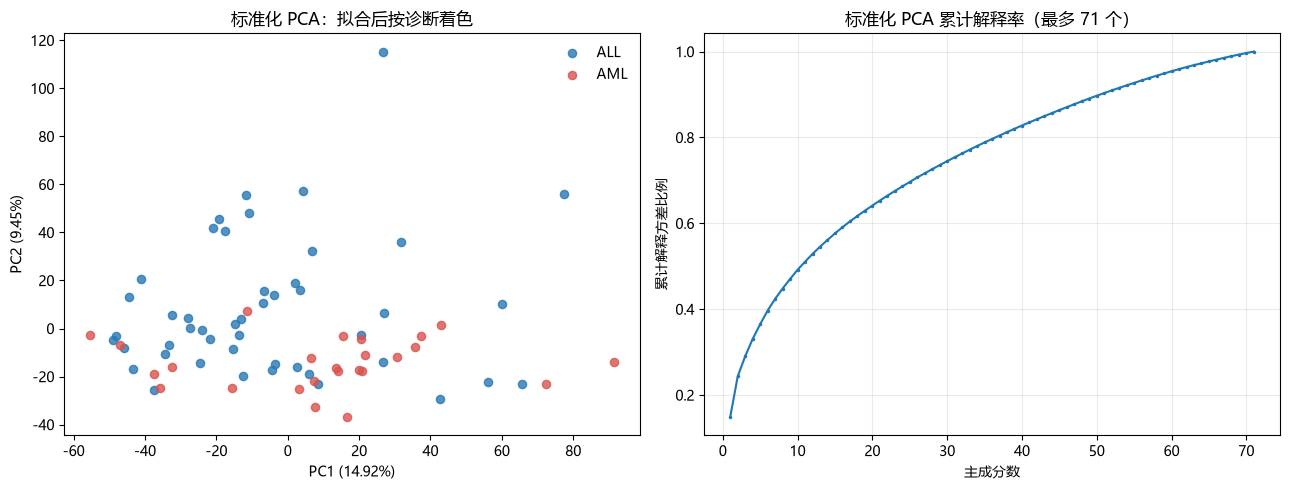

累计解释率：


,主成分数,累计解释率
0,1,14.92%
1,2,24.37%
2,5,36.50%
3,10,49.18%
4,20,64.13%
5,71,100.00%


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_scaled = PCA().fit(X_scaled)
scores_scaled = pca_scaled.transform(X_scaled)
pca_raw = PCA().fit(X)  # PCA 会中心化；这里不额外按列标准化
scores_raw = pca_raw.transform(X)

print(f'标准化后列均值绝对值最大值：{np.abs(X_scaled.mean(axis=0)).max():.3e}')
print(f'标准化后列总体标准差范围：{X_scaled.std(axis=0).min():.6f} 至 {X_scaled.std(axis=0).max():.6f}')
print(f'标准化 PCA：PC1={pca_scaled.explained_variance_ratio_[0]:.4%}，PC2={pca_scaled.explained_variance_ratio_[1]:.4%}，合计={pca_scaled.explained_variance_ratio_[:2].sum():.4%}')
print(f'原尺度 PCA：PC1={pca_raw.explained_variance_ratio_[0]:.4%}，PC2={pca_raw.explained_variance_ratio_[1]:.4%}，合计={pca_raw.explained_variance_ratio_[:2].sum():.4%}')

standardized_weights = pd.Series(pca_scaled.components_[0], index=feature_columns)
standardized_top = standardized_weights.loc[standardized_weights.abs().nlargest(5).index]
raw_weights = pd.Series(pca_raw.components_[0], index=feature_columns)
raw_top = raw_weights.loc[raw_weights.abs().nlargest(5).index]
loading_table = pd.DataFrame({
    '标准化 PC1 探针': standardized_top.index,
    '标准化 PC1 带符号权重': standardized_top.values,
    '原尺度 PC1 探针': raw_top.index,
    '原尺度 PC1 带符号权重': raw_top.values,
})
print('PC1 绝对权重最大的 5 个探针（components_ 方向权重，带符号）：')
display(loading_table.round(6))

cumulative = np.cumsum(pca_scaled.explained_variance_ratio_[:len(df) - 1])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {'ALL': '#2878B5', 'AML': '#D9534F'}
for label in ['ALL', 'AML']:
    mask = y.to_numpy() == label
    axes[0].scatter(scores_scaled[mask, 0], scores_scaled[mask, 1], label=label, s=35, alpha=0.8, color=colors[label])
axes[0].set_xlabel(f'PC1 ({pca_scaled.explained_variance_ratio_[0]:.2%})')
axes[0].set_ylabel(f'PC2 ({pca_scaled.explained_variance_ratio_[1]:.2%})')
axes[0].set_title('标准化 PCA：拟合后按诊断着色')
axes[0].legend(frameon=False)
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative, marker='.', markersize=3)
axes[1].set_xlabel('主成分数')
axes[1].set_ylabel('累计解释方差比例')
axes[1].set_title('标准化 PCA 累计解释率（最多 71 个）')
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'hw04_pca_results.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

cumulative_table = pd.DataFrame({
    '主成分数': [1, 2, 5, 10, 20, 71],
    '累计解释率': [pca_scaled.explained_variance_ratio_[:k].sum() for k in [1, 2, 5, 10, 20, 71]],
})
print('累计解释率：')
display(cumulative_table.assign(累计解释率=cumulative_table['累计解释率'].map(lambda value: f'{value:.2%}')))

**解释与边界：**标准化令每个探针在当前样本中的尺度相近，避免大尺度探针仅凭量纲主导 PCA；代价是低变异探针也会被放大，可能放大噪声。原尺度 PCA 更受高方差探针影响，因此两种尺度处理可能得到不同的 PC1 权重和解释率。PC1 是当前输入矩阵中方差最大的方向，不等于最能区分 ALL/AML 的方向，也不代表一个基因。7,129 个探针不等于 7,129 个不同基因；探针名需要额外注释，不能直接当作致病基因。

## 任务 3：UMAP 上的簇可以相信到什么程度？

使用任务 2 的同一标准化矩阵，不按诊断筛选探针。UMAP 基线为 `n_neighbors=15`、`min_dist=0.1`、`metric='euclidean'`、`random_state=42`、`n_jobs=1`。对照分别只改变邻居数、`min_dist` 或随机种子，诊断只在拟合后用于着色。

| 对照维度 | PCA | UMAP |
|---|---|---|
| 线性/非线性 | 线性变换 | 非线性嵌入 |
| 优化或保留的主要信息 | 依次最大化总体方差 | 主要服务于局部邻域结构展示 |
| 坐标轴含义 | 主成分方向是输入特征的线性组合 | 坐标轴无直接物理含义 |
| 方差解释率 | 可报告每个 PC 的解释率 | 不提供 PCA 式方差解释率 |
| 局部邻域与全局距离 | 投影会丢失信息，二维距离不等于完整高维距离 | 邻近点可作探索；全局距离、岛屿间距、方向和面积不可直接解释 |
| 参数与随机性 | 主要由输入尺度、保留维数和拟合数据决定 | `n_neighbors`、`min_dist` 和随机种子会影响嵌入 |
| 预测时如何避免泄露 | 标准化、PCA 和分类器只在训练折拟合 | 若用于预测，UMAP、预处理和模型也只在训练折拟合；验证折只 transform，不参与拟合或调参 |

为比较设置下的局部结构，代码计算每个点在二维嵌入中的 10 近邻集合与基线的 Jaccard 重合率。它只是图形稳定性的描述，不是生物学验证或预测性能。

各对照与基线的局部邻域重合（0 表示无重合，1 表示完全相同）：


,对照,每样本 10 近邻 Jaccard 均值,每样本 10 近邻 Jaccard 中位数
0,邻居数 5,0.471,0.538
1,min_dist 0.5,0.538,0.538
2,随机种子 7,0.541,0.538


坐标与样本编号对应表已保存：.tmp\dimension-reduction\student-results\hw04_sample_coordinates.csv


,sample_id,diagnosis,PCA_PC1,PCA_PC2,基线_1,基线_2,邻居数_5_1,邻居数_5_2,min_dist_0_5_1,min_dist_0_5_2,随机种子_7_1,随机种子_7_2
0,G001,ALL,27.105207,6.448490,7.527618,1.749259,10.055384,1.022408,4.242846,6.732675,0.928812,5.430337
1,G002,ALL,3.507419,15.845801,7.233461,0.753453,9.536812,2.273381,4.321175,8.143794,1.712362,6.443752
2,G003,ALL,60.006379,10.392307,7.544736,1.512743,9.701388,1.346992,4.501159,6.984841,1.285627,5.706972
3,G004,ALL,20.640386,-2.623372,7.338019,2.063425,10.379709,0.996700,4.019698,6.123560,1.241458,5.141459
4,G005,ALL,-21.012018,41.794160,7.786791,0.032986,6.518684,0.503266,4.863666,9.381099,1.409877,7.700765


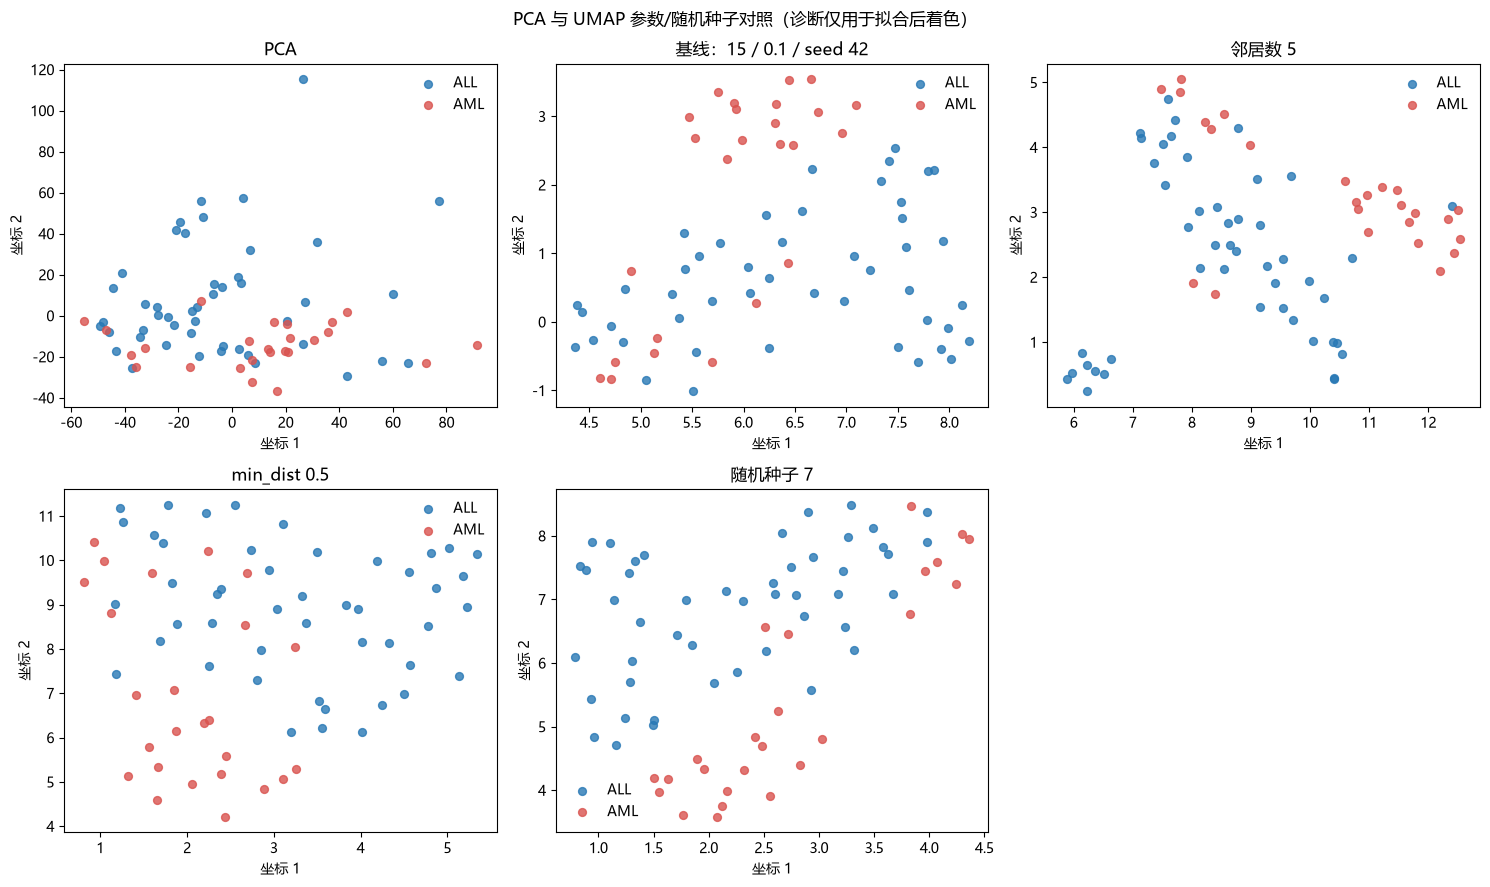

In [4]:
from sklearn.neighbors import NearestNeighbors

umap_configs = {
    '基线：15 / 0.1 / seed 42': {'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 42},
    '邻居数 5': {'n_neighbors': 5, 'min_dist': 0.1, 'random_state': 42},
    'min_dist 0.5': {'n_neighbors': 15, 'min_dist': 0.5, 'random_state': 42},
    '随机种子 7': {'n_neighbors': 15, 'min_dist': 0.1, 'random_state': 7},
}
embeddings = {}
for name, config in umap_configs.items():
    reducer = umap.UMAP(n_components=2, metric='euclidean', n_jobs=1, **config)
    embeddings[name] = reducer.fit_transform(X_scaled)

def neighbor_sets(coordinates, k=10):
    indices = NearestNeighbors(n_neighbors=k + 1).fit(coordinates).kneighbors(
        coordinates, return_distance=False
    )[:, 1:]
    return [set(row) for row in indices]

baseline_neighbors = neighbor_sets(embeddings['基线：15 / 0.1 / seed 42'])
overlap_rows = []
for name in list(umap_configs)[1:]:
    comparison_neighbors = neighbor_sets(embeddings[name])
    jaccard = [len(base & comparison) / len(base | comparison)
               for base, comparison in zip(baseline_neighbors, comparison_neighbors)]
    overlap_rows.append({
        '对照': name,
        '每样本 10 近邻 Jaccard 均值': np.mean(jaccard),
        '每样本 10 近邻 Jaccard 中位数': np.median(jaccard),
    })
overlap_table = pd.DataFrame(overlap_rows)
print('各对照与基线的局部邻域重合（0 表示无重合，1 表示完全相同）：')
display(overlap_table.round(3))

coordinate_table = pd.DataFrame({
    'sample_id': df['sample_id'],
    'diagnosis': y,
    'PCA_PC1': scores_scaled[:, 0],
    'PCA_PC2': scores_scaled[:, 1],
})
for name, coordinates in embeddings.items():
    prefix = name.split('：')[0].replace(' ', '_').replace('.', '_')
    coordinate_table[f'{prefix}_1'] = coordinates[:, 0]
    coordinate_table[f'{prefix}_2'] = coordinates[:, 1]
coordinate_path = RESULTS_DIR / 'hw04_sample_coordinates.csv'
coordinate_table.to_csv(coordinate_path, index=False)
print(f'坐标与样本编号对应表已保存：{coordinate_path.relative_to(ROOT)}')
display(coordinate_table.head())

plot_items = [('PCA', scores_scaled[:, :2])] + list(embeddings.items())
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, coordinates) in zip(axes.flat, plot_items):
    for label in ['ALL', 'AML']:
        mask = y.to_numpy() == label
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], label=label,
                   s=32, alpha=0.8, color=colors[label])
    ax.set_title(title)
    ax.set_xlabel('坐标 1')
    ax.set_ylabel('坐标 2')
    ax.legend(frameon=False)
axes.flat[-1].set_visible(False)
fig.suptitle('PCA 与 UMAP 参数/随机种子对照（诊断仅用于拟合后着色）')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'hw04_pca_umap_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

**观察与边界：**比较基线与三个对照的近邻重合表，可见局部关系仅部分稳定。参数或随机种子变化会改变图形结构，不能只挑最分开的那张图。UMAP 可用于展示复杂高维数据的候选局部结构，但岛屿数量、岛屿间距离、方向和面积不能直接代表真实亚型数、疾病机制或组间生物距离。本数据没有可用于核对的中心/批次字段，不能声称已排除批次影响；UMAP 图也不能证明新患者预测性能。

## 任务 4：退出卡

### 退出卡：主张—证据—推理—边界（四句话）

1. **主张：**二维图上 ALL 与 AML 有一定分离，但该分离本身不足以证明发现疾病机制，也不能证明模型能预测新患者。
2. **证据：**标准化 PCA 的 PC1、PC2 解释率由上方代码实际输出；UMAP 对照的近邻重合率也由表格实际输出。
3. **推理：**PCA 最大化总体方差而非诊断区分，且 UMAP 参数对照显示局部邻域仅部分稳定，因此不能只凭一张看起来分开的图作强结论。
4. **边界与下一步：**本数据不是独立临床验证且缺少批次字段；要支持机制需在独立、含批次/临床信息的队列复现并做实验验证，预测能力需用严格隔离的新样本评估。

三道作业的个人回答已填写在同目录的 `38720260158057-赵晨雨-工作单.md`，与本 notebook 的实际分析结果对应。

## 运行记录与提交前自查

- Python 与关键软件包版本：由第一个代码单元实际打印。
- 输入特征：排除 `sample_id`、`original_split`、`diagnosis` 后的全部 7,129 个探针。
- 描述性标准化、PCA、UMAP 拟合范围：全部 72 个样本；诊断仅用于拟合后着色。
- UMAP：基线 `n_neighbors=15`、`min_dist=0.1`、`metric='euclidean'`、`random_state=42`、`n_jobs=1`；三个对照各只改变一个因素。
- 可选交叉验证只使用原始 38 个 train 样本；StandardScaler、PCA、分类器均在折内拟合，未用原始 test 样本评分或调参。该小样本结果不是临床验证。
- AI 使用：使用 AI 协助整理代码、解释术语和检查流程。所有数值来自本 notebook 实际计算。提交前请从头运行、查看图表并确认能用自己的话解释结果。
- 图和坐标表可重新生成在项目根目录 `.tmp/dimension-reduction/student-results/`，不应把缓存或数据副本加入提交。
- [ ] 四项任务、图、代码和实际输出齐全；[ ] 说明了拟合范围与信息泄露边界；[ ] 提交时只添加本人的 HW04 目录。